In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"C:\Users\LATO\Documents\Customer Churn\data\customer-churn-data.csv"

df = pd.read_csv(file_path)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

sns.set_theme(style="whitegrid")

In [3]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)

print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


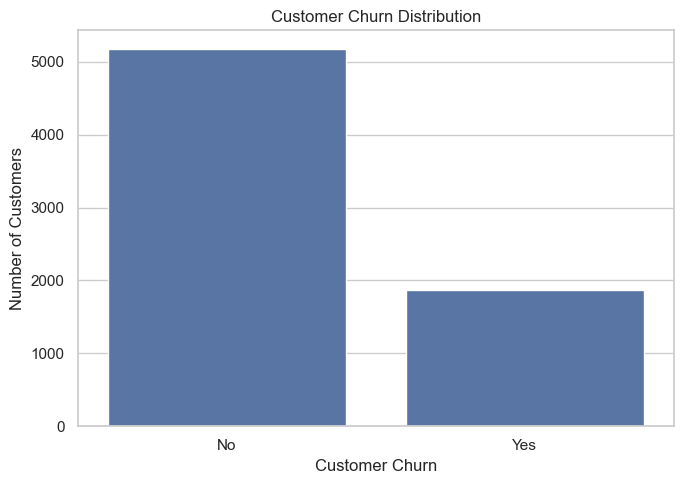

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [5]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn = contract_churn.round(2)

print(contract_churn)

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


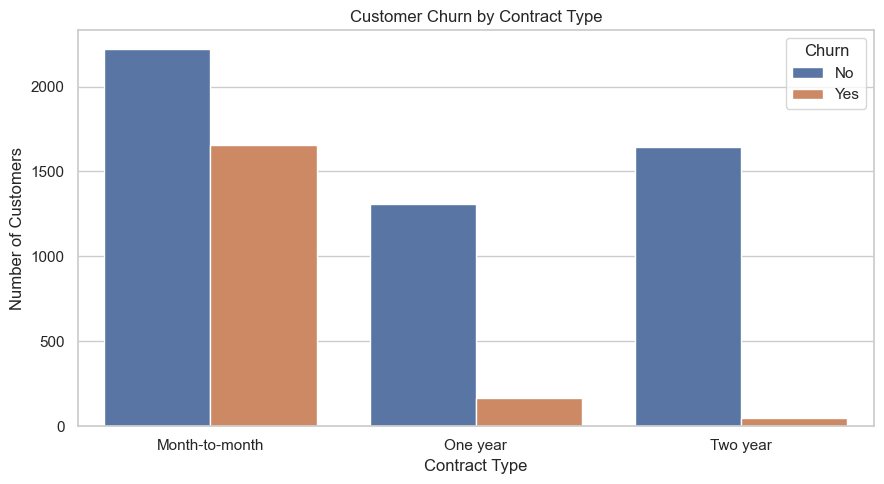

In [6]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.tight_layout()
plt.show()

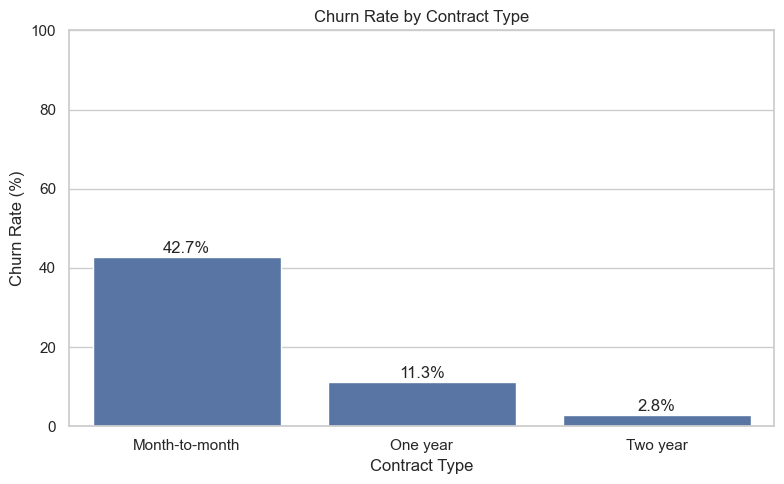

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64


In [7]:
churn_rates = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("Contract")["ChurnFlag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_rates.index,
    y=churn_rates.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for i, value in enumerate(churn_rates.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

print(churn_rates.round(2))

## Month-to-month customers churn at about 15 times the rate of two-year contract customers. Longer contracts are associated with better customer retention, although this analysis alone does not prove that contract length causes lower churn.

In [8]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months",
            "25–48 months", "49–72 months"]
)

tenure_churn = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("TenureGroup", observed=False)["ChurnFlag"]
      .agg(["count", "mean"])
)

tenure_churn["ChurnRate"] = (tenure_churn["mean"] * 100).round(2)
tenure_churn = tenure_churn.rename(
    columns={"count": "Customers"}
)

print(tenure_churn[["Customers", "ChurnRate"]])

              Customers  ChurnRate
TenureGroup                       
0–12 months        2186      47.44
13–24 months       1024      28.71
25–48 months       1594      20.39
49–72 months       2239       9.51


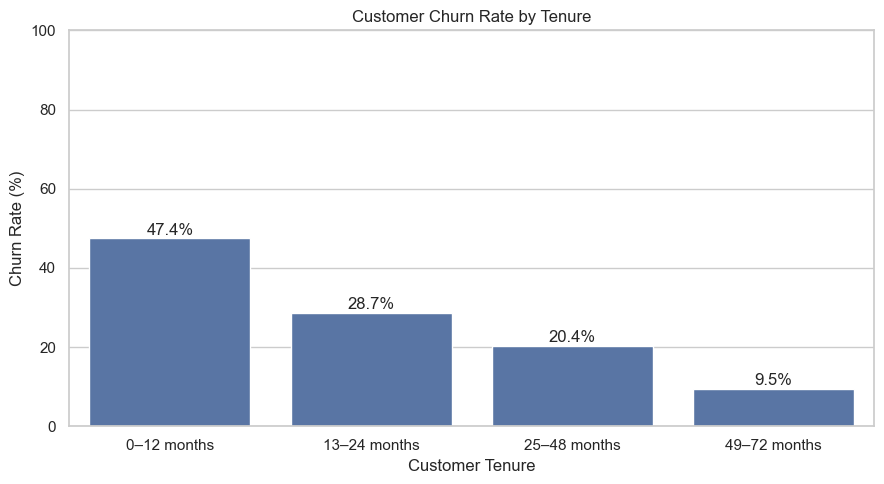

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tenure_churn.reset_index(),
    x="TenureGroup",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(tenure_churn["ChurnRate"]):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

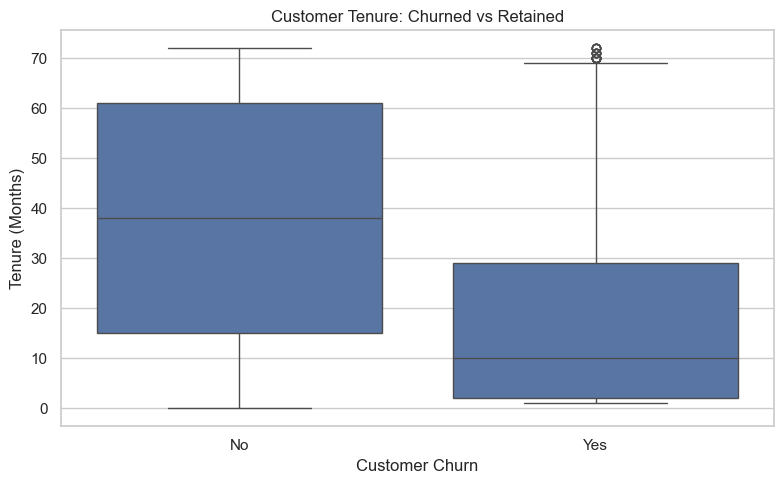

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure: Churned vs Retained")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

## Key findings:
- New customers (0–12 months) have the highest churn rate at 47.44%.
- Long-term customers (49–72 months) have the lowest rate at 9.51%.
- Churn decreases consistently as customer tenure increases.
- The company should focus retention efforts on customers during their first year.

In [11]:
monthly_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "std"]
).round(2)

print(monthly_summary)

       count   mean  median    std
Churn                             
No      5174  61.27   64.43  31.09
Yes     1869  74.44   79.65  24.67


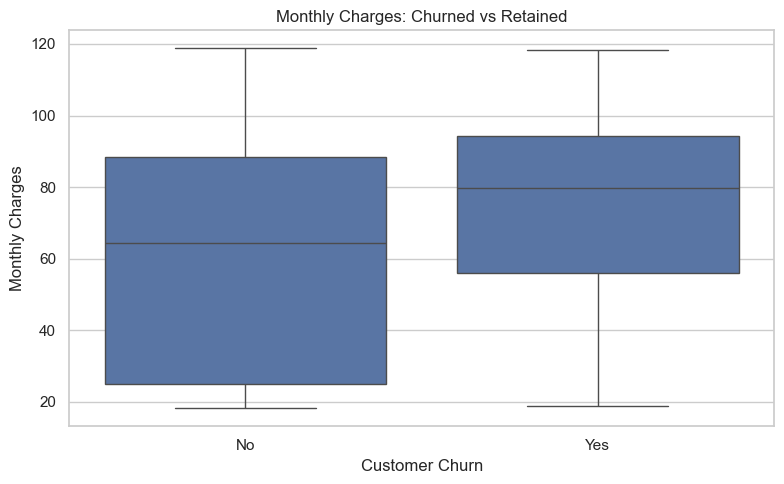

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges: Churned vs Retained")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [13]:
df["ChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 100, 120],
    labels=["Low (≤35)", "Medium (35–70)",
            "High (70–100)", "Very High (>100)"],
    include_lowest=True
)

charge_churn = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("ChargeGroup", observed=False)["ChurnFlag"]
      .agg(["count", "mean"])
)

charge_churn["ChurnRate"] = (charge_churn["mean"] * 100).round(2)

print(charge_churn[["count", "ChurnRate"]])

                  count  ChurnRate
ChargeGroup                       
Low (≤35)          1735      10.89
Medium (35–70)     1725      23.94
High (70–100)      2681      37.82
Very High (>100)    902      28.05


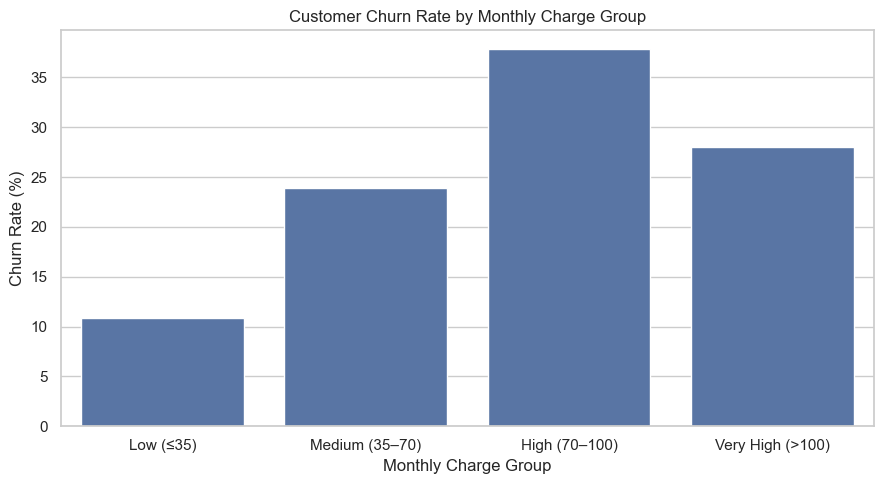

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=charge_churn.reset_index(),
    x="ChargeGroup",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Monthly Charge Group")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

## Key findings:
- The high-charge group has the highest churn rate at 37.82%.
- Low-charge customers have the lowest churn rate at 10.89%.
- Churn does not increase continuously: the very-high-charge group has a lower rate than the high-charge group.
- Pricing, service combinations, and customer expectations may help explain these differences; further analysis is needed.

In [15]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


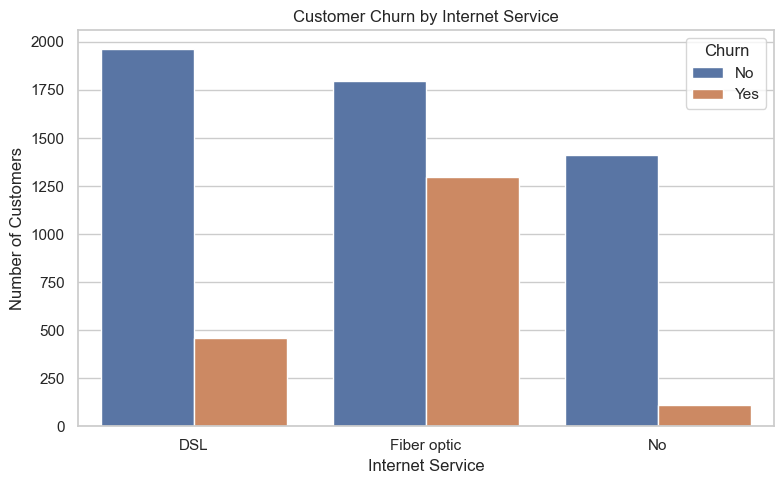

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

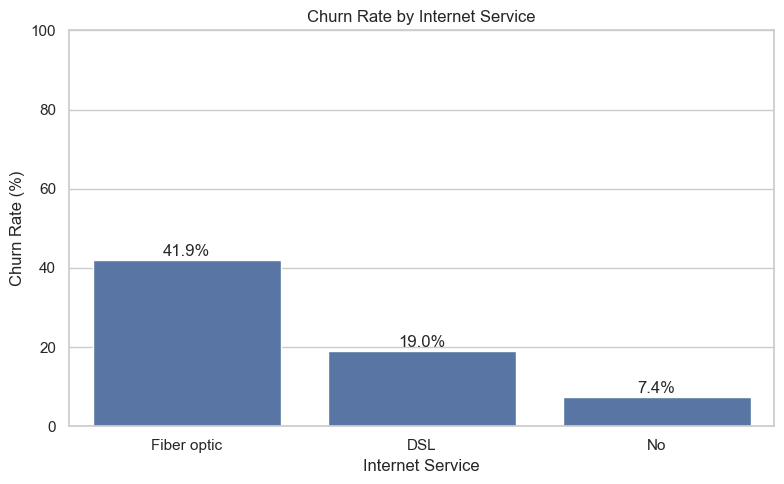

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: ChurnFlag, dtype: float64


In [17]:
internet_rates = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("InternetService")["ChurnFlag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=internet_rates.index,
    y=internet_rates.values
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for i, value in enumerate(internet_rates.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

print(internet_rates.round(2))

## Key findings:
- Fiber-optic customers have the highest churn rate at 41.89%.
- Their churn rate is more than twice the DSL rate.
- Customers without internet service have the lowest churn rate.
- Further analysis should investigate whether pricing, contracts, or support services help explain fiber-optic churn.

In [18]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


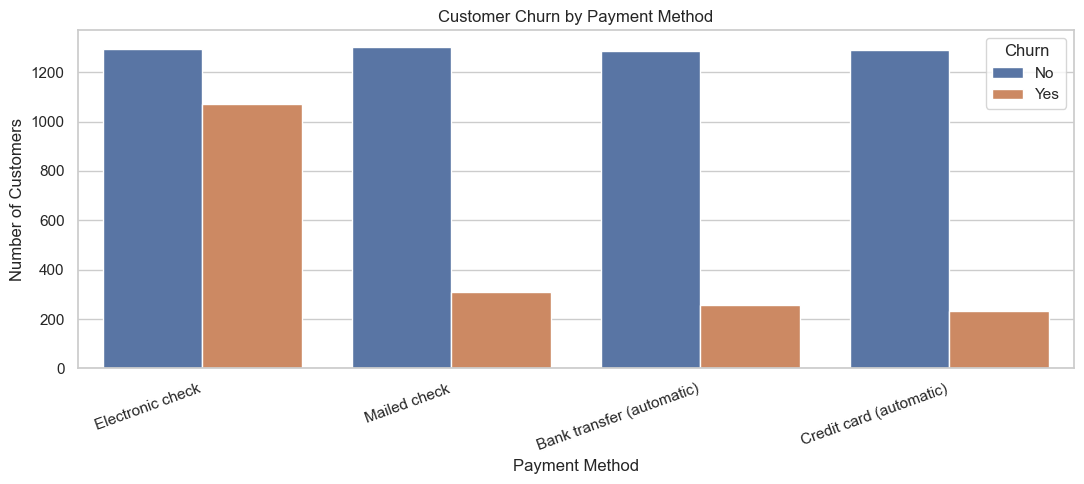

In [19]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

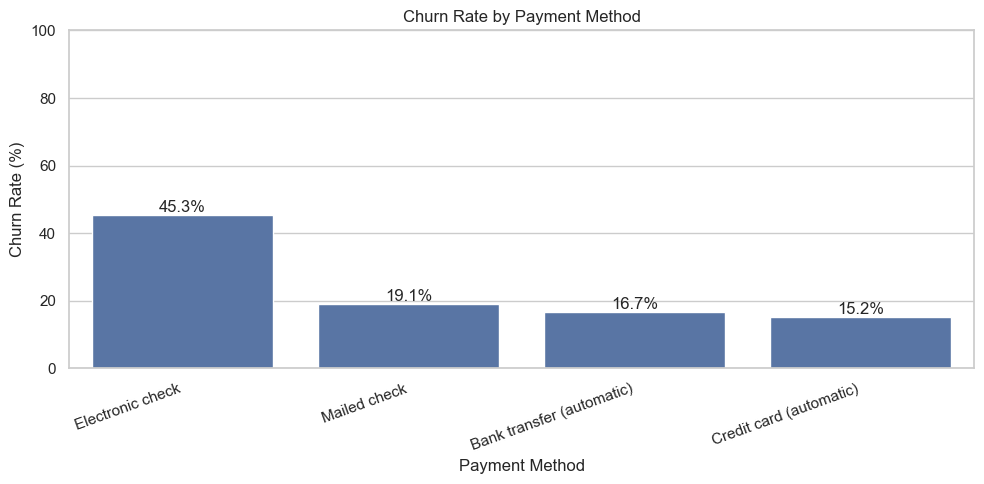

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: ChurnFlag, dtype: float64


In [20]:
payment_rates = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("PaymentMethod")["ChurnFlag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=payment_rates.index,
    y=payment_rates.values
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)

for i, value in enumerate(payment_rates.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

print(payment_rates.round(2))

In [ ]:
## Key findings:
- Electronic-check customers have the highest churn rate at 45.29%.
- Automatic credit-card payments have the lowest rate at 15.24%.
- Electronic-check churn is almost three times the automatic credit-card rate.
- The company could investigate whether payment convenience, customer preferences, or other customer characteristics explain this difference.

In [21]:
service_columns = [
    "TechSupport",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection"
]

for col in service_columns:
    print(f"\nChurn rate by {col}:")

    rates = (
        df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
          .groupby(col)["ChurnFlag"]
          .mean()
          .mul(100)
          .round(2)
    )

    print(rates)


Churn rate by TechSupport:
TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: ChurnFlag, dtype: float64

Churn rate by OnlineSecurity:
OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: ChurnFlag, dtype: float64

Churn rate by OnlineBackup:
OnlineBackup
No                     39.93
No internet service     7.40
Yes                    21.53
Name: ChurnFlag, dtype: float64

Churn rate by DeviceProtection:
DeviceProtection
No                     39.13
No internet service     7.40
Yes                    22.50
Name: ChurnFlag, dtype: float64


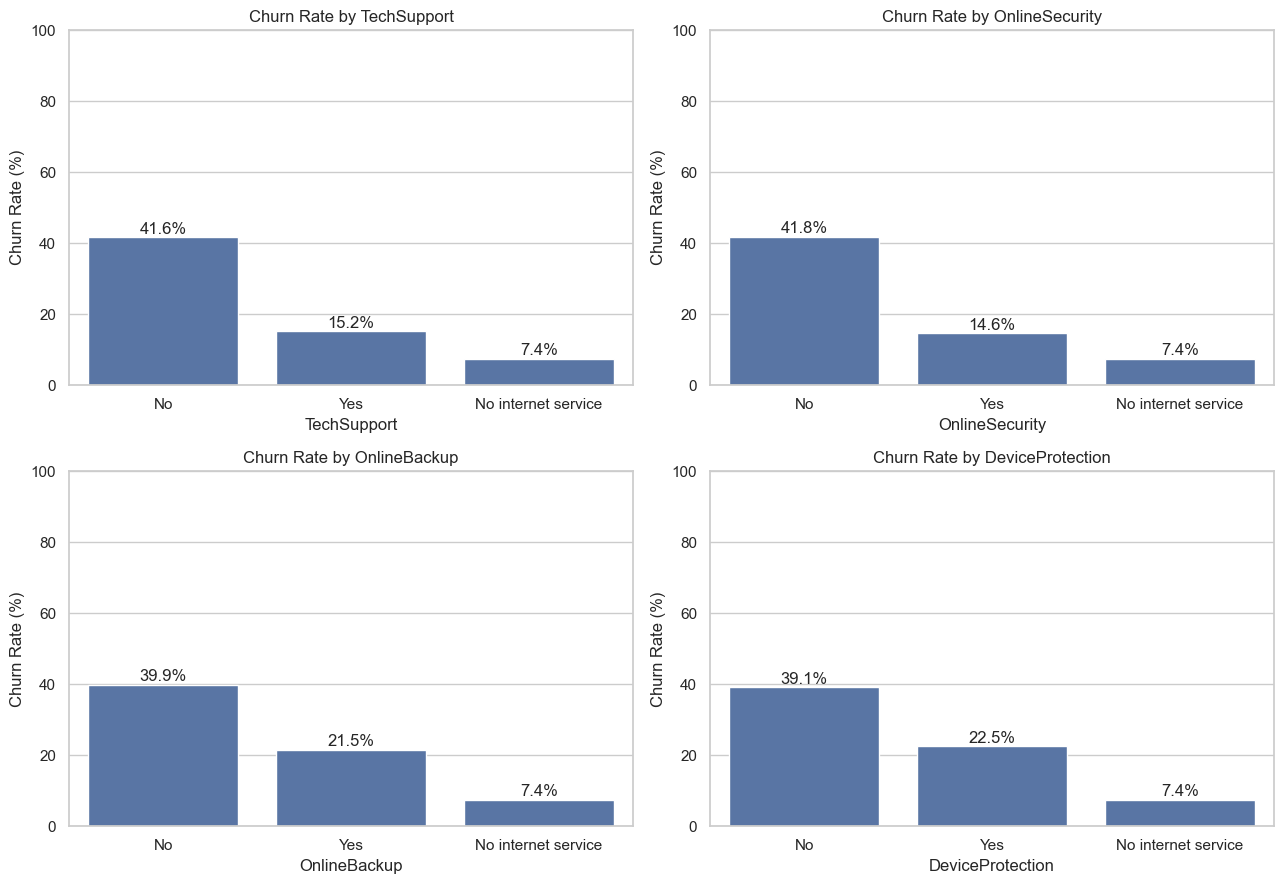

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, ax in zip(service_columns, axes.flatten()):
    rates = (
        df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
          .groupby(col)["ChurnFlag"]
          .mean()
          .mul(100)
          .sort_values(ascending=False)
    )

    sns.barplot(x=rates.index, y=rates.values, ax=ax)

    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 100)

    for i, value in enumerate(rates.values):
        ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

In [ ]:
## Business insights:
- Customers without online security have a 41.77% churn rate.
- Customers without technical support have a 41.64% churn rate.
- Backup and device protection also show lower churn among subscribers.
- The company should investigate service satisfaction and support needs among customers who lack these services.

In [23]:
demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

for col in demographic_columns:
    print(f"\nChurn rate by {col}:")

    rates = (
        df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
          .groupby(col)["ChurnFlag"]
          .mean()
          .mul(100)
          .round(2)
    )

    print(rates)


Churn rate by gender:
gender
Female    26.92
Male      26.16
Name: ChurnFlag, dtype: float64

Churn rate by SeniorCitizen:
SeniorCitizen
0    23.61
1    41.68
Name: ChurnFlag, dtype: float64

Churn rate by Partner:
Partner
No     32.96
Yes    19.66
Name: ChurnFlag, dtype: float64

Churn rate by Dependents:
Dependents
No     31.28
Yes    15.45
Name: ChurnFlag, dtype: float64


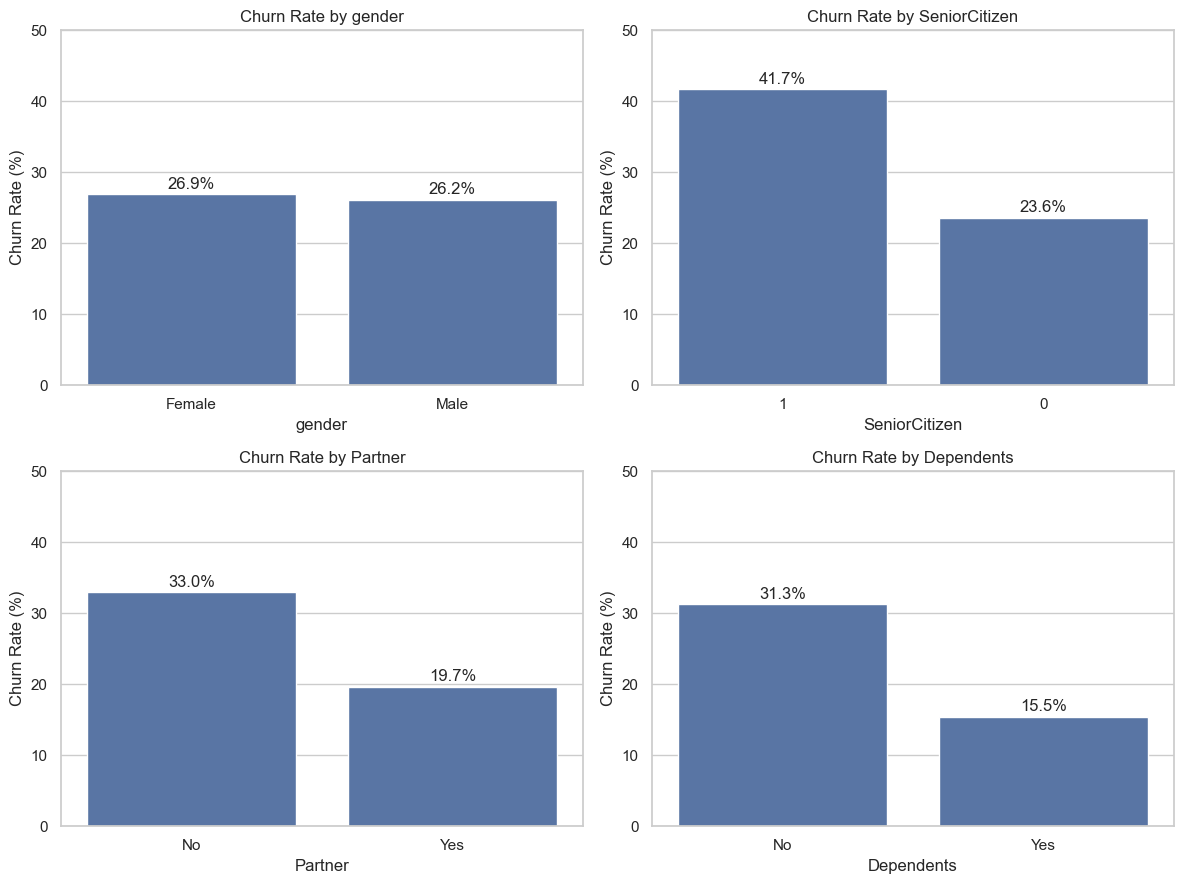

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for col, ax in zip(demographic_columns, axes.flatten()):
    rates = (
        df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
          .groupby(col)["ChurnFlag"]
          .mean()
          .mul(100)
          .sort_values(ascending=False)
    )

    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax)

    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 50)

    for i, value in enumerate(rates.values):
        ax.text(i, value + 0.8, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

In [25]:
df["SeniorCitizenLabel"] = df["SeniorCitizen"].map({
    0: "Non-senior",
    1: "Senior"
})

## Key findings
- Gender shows only a small difference in churn rates.
- Senior citizens have a higher churn rate than non-senior customers.
- Customers without partners have higher churn than customers with partners.
- Customers without dependents also show higher churn rates.

In [26]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print(
    df.groupby("Churn")[numeric_columns]
      .agg(["mean", "median"])
      .round(2)
)

      tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2555.34  1683.60
Yes    17.98   10.0          74.44  79.65      1531.80   703.55


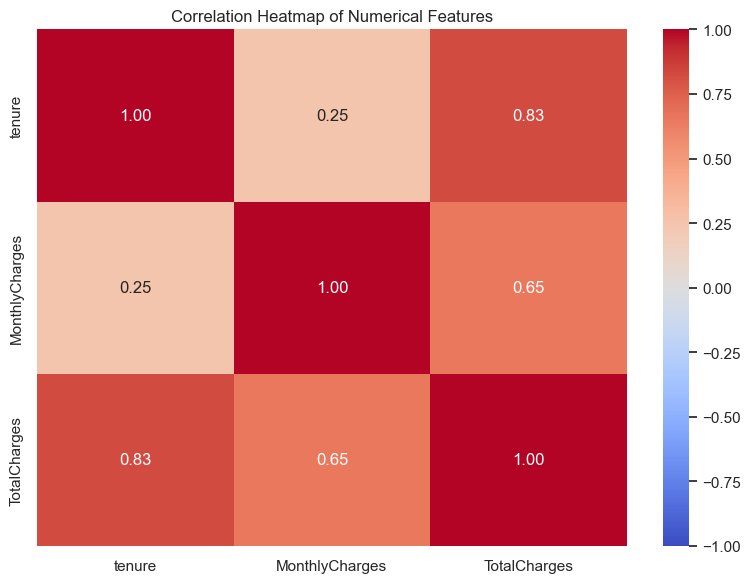

In [27]:
plt.figure(figsize=(8, 6))

correlation = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

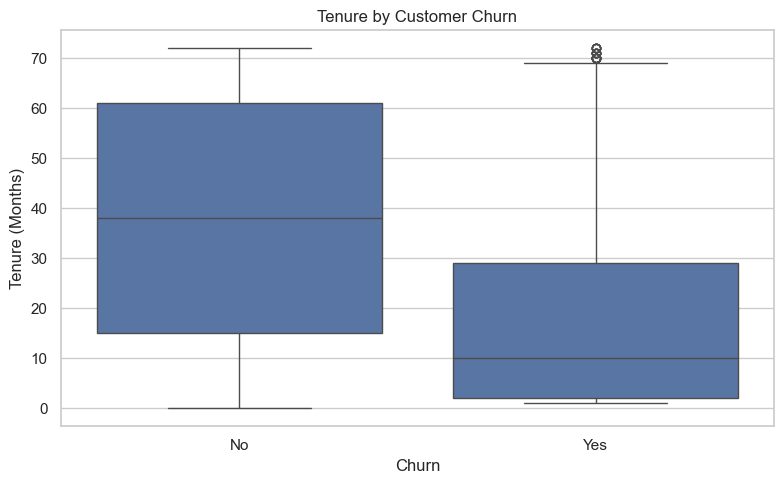

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure by Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

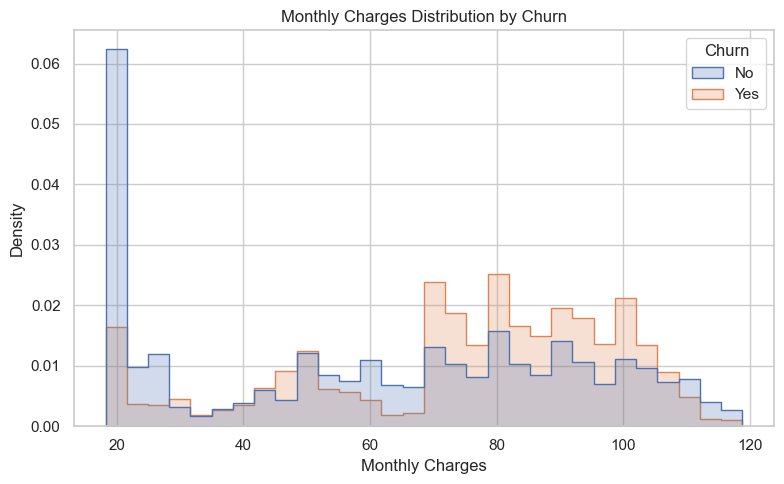

In [29]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

# Step 10: EDA Summary and Key Findings

## 1. Overall Churn
- The dataset contains 7,043 customers.
- 1,869 customers churned, representing 26.54% of all customers.
- Customer churn is an important business problem.

## 2. Key Factors Associated with Churn

### Contract Type
- Month-to-month customers have a 42.71% churn rate.
- Two-year contract customers have a 2.83% churn rate.
- Contract type is strongly associated with customer retention.

### Customer Tenure
- Customers with 0–12 months of tenure have a 47.44% churn rate.
- Customers with 49–72 months of tenure have a 9.51% churn rate.
- Early customer retention should be a business priority.

### Monthly Charges
- Customers paying $70–$100 monthly have a 37.82% churn rate.
- Customers paying $35 or less monthly have a 10.89% churn rate.
- Pricing and perceived value may be worth investigating.

### Internet Service
- Fiber-optic customers have a 41.89% churn rate.
- DSL customers have an 18.96% churn rate.
- Customers without internet service have a 7.40% churn rate.

### Payment Method
- Electronic-check customers have a 45.29% churn rate.
- Automatic credit-card payment customers have a 15.24% churn rate.
- Payment experience and customer characteristics warrant further investigation.

### Support and Security Services
- Customers without technical support have a 41.64% churn rate.
- Customers without online security have a 41.77% churn rate.
- These services may be relevant to customer retention.

### Customer Demographics
- Senior citizens have a 41.68% churn rate.
- Customers without partners have a 32.96% churn rate.
- Customers without dependents have a 31.28% churn rate.
- Gender differences in churn are small.

## 3. Numerical Relationships
- Churned customers have a median tenure of 10 months, compared with 38 months for retained customers.
- Churned customers have higher median monthly charges: $79.65 versus $64.43.
- Tenure and total charges have a strong positive correlation of 0.83.
- Monthly charges and total charges have a positive correlation of 0.65.
- Tenure and monthly charges have a weaker positive correlation of 0.25.

## 4. Business Recommendations
1. Develop targeted retention programs for new customers.
2. Encourage suitable longer-term contract options.
3. Investigate pricing and perceived value among high-churn customer groups.
4. Review the experience of fiber-optic and electronic-check customers.
5. Evaluate whether technical support and online security improve retention.

## 5. Conclusion
Exploratory data analysis identified several customer groups associated with higher churn, particularly month-to-month customers, customers with shorter tenure, and customers with higher monthly charges. These findings will guide feature engineering, statistical analysis, and predictive model development.

**Important:** These are associations, not proof of causation. Further statistical testing and predictive modeling are needed to evaluate their usefulness.